# Washington tire market opportunity (POC)

## 1. Summary

We asked which Washington counties have independent tire-dealer sales above what registered vehicles and dealership activity predict, and growing faster than the local vehicle fleet. Using state taxable-sales data (2015–2026) and vehicle registrations, we modelled expected tire-dealer sales with two dealer-activity controls (Census dealer employment as primary, dealer taxable sales as secondary). We flagged counties above expectation beyond typical model error whose real tire-dealer growth beat registered-vehicle growth from 2019 to 2025. **Kittitas is the one robust candidate** (flagged under both controls) and **Asotin is on watch** (flagged under dealer sales only, no Census data). The main caveat: each county's growth comes mostly from a single city (Cle Elum 73%, Clarkston 96%), and a tire-dealer share gain could come from dealerships, big-box or online sellers alike, so these are **candidates to investigate, not proof** that dealerships are losing tire business.


In [1]:
import pandas as pd
from IPython.display import Markdown
from wa_tire import config, plots, signals
from wa_tire.build import load_processed
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

## 2. Data

This section shows where the numbers come from, what period they cover, and which counties were left out and why.

- **Tire and dealer sales:** WA Dept. of Revenue, Taxable Retail Sales (local) builder, retail sales tax, quarterly 2015Q1–2026Q1. Tire dealers = NAICS 441320 (to 2022Q1) + 441340 (from 2022Q2); new-car dealers = 441110. Cities and unincorporated areas are summed to counties; transit-area (PTBA) and empty `xx99` codes are dropped (`reports/location_codes.md`).
- **Dealer employment (primary dealer measure):** Census County Business Patterns, NAICS 441110, mid-March employment, 2017–2023. Small counties are not published.
- **Demand:** WA Dept. of Licensing registration transactions, Passenger Vehicle + Truck, by owner's county, 2017–2025 (data.wa.gov `hmzg-s6q4`).
- **Prices:** BLS CPI-U Tires (`CUUR0000SETC01`) for tire sales and New vehicles (`CUUR0000SETA01`) for dealer sales; constant 2025 dollars.
- **Exclusions:** a county-quarter counts as hidden when suppressed cells could hold more than 25% of tire-dealer taxpayers. Counties hidden in more than 25% of quarters are excluded from all views. Each view also drops counties that lack its dealer measure in any model year.

In [2]:
coverage = load_processed("coverage")
coverage.loc[coverage["excluded"], ["county", "hidden_quarter_share", "reason"]]

,county,hidden_quarter_share,reason
6,Columbia,0.467,tire data hidden in 47% of quarters
8,Douglas,0.356,tire data hidden in 36% of quarters
11,Garfield,0.622,tire data hidden in 62% of quarters; a model year with no disclosed tire-dealer sales
13,Grays Harbor,0.333,tire data hidden in 33% of quarters
21,Lincoln,0.778,tire data hidden in 78% of quarters
24,Pacific,0.533,tire data hidden in 53% of quarters
25,Pend Oreille,0.556,tire data hidden in 56% of quarters
29,Skamania,0.733,tire data hidden in 73% of quarters
34,Wahkiakum,0.511,tire data hidden in 51% of quarters
37,Whitman,0.911,tire data hidden in 91% of quarters


In [3]:
load_processed("view_summary")

,view,measure,model_years,test_years,counties,dropped_no_dealer_data,top_candidates
0,cbp_emp,New-car dealer employment (CBP),2017-2023,2022-2023,20,"Adams, Asotin, Ferry, Island, Jefferson, Klickitat, Mason, San Juan, Stevens",Kittitas
1,sales,New-car dealer real taxable sales (DOR),2017-2025,2022-2025,29,NaN,"Asotin, Kittitas"


## 3. Exploration

This chart shows statewide real taxable sales for tire dealers and new-car dealers, each indexed to its 2019 average.

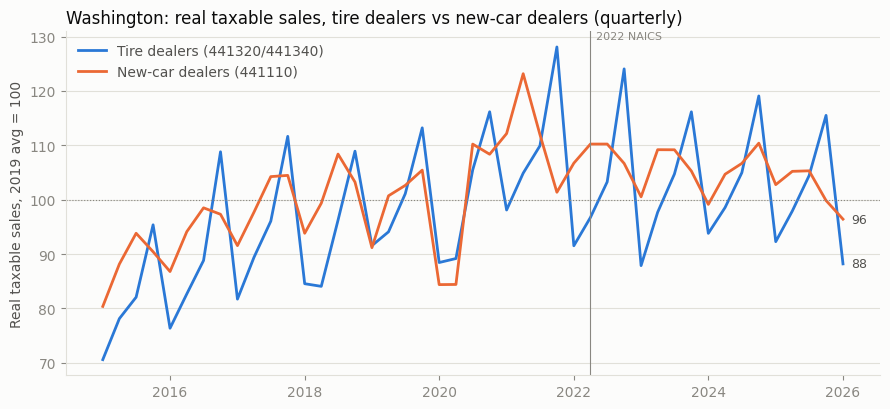

In [4]:
cq = load_processed("county_quarter")
plots.statewide_index(cq);

## 4. Model

This section shows how expected tire-shop sales are estimated for each county.

- **Baseline:** real tire-dealer sales per registered vehicle × county vehicles.
- **Model:** OLS of log real tire-dealer sales on log vehicles and log dealer activity, with year effects (standard errors clustered by county).
- **Dealer activity** is CBP new-car dealer employment (primary view) or DOR real new-car-dealer sales (secondary view).
- **Split:** train 2017–2021; test 2022–2023 (CBP view) or 2022–2025 (sales view).
- Dealer activity appears **only in this level model**. The growth signal compares tire sales with registered vehicles.
- **Calibration:** both methods are scaled each year to the actual total of the counties in the view, so the test measures how well each method *allocates* sales across counties.

In [5]:
load_processed("coefficients_cbp_emp")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.652,0.163,0.000,100,0.955
1,log_dealer,0.148,0.142,0.298,100,0.955


In [6]:
load_processed("coefficients_sales")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.398,0.213,0.062,145,0.821
1,log_dealer,0.348,0.165,0.035,145,0.821


## 5. Evaluation

These tables compare baseline and model errors on the test years for each view (MAPE = mean absolute percentage error).

In [7]:
load_processed("evaluation_cbp_emp")

,method,MAPE,mean_abs_log_error,n_county_years,years
0,baseline,0.207,0.237,40,2022-2023
1,model,0.137,0.132,40,2022-2023


In [8]:
load_processed("evaluation_sales")

,method,MAPE,mean_abs_log_error,n_county_years,years
0,baseline,0.774,0.358,116,2022-2025
1,model,0.435,0.305,116,2022-2025


## 6. Results

This section ranks counties on both signals, shows which counties are flagged under each dealer measure, and lists hypotheses other than dealer loss.

- **Residual flag:** actual above the out-of-sample expectation in every recent test year, *and* the mean recent log residual is more than 1× the model's typical error (median absolute test log error). `residual_z` is that ratio.
- **Growth flag:** top quartile on the relative growth gap, with the gap > 0 and real tire growth > 0. The relative gap is (county − state tire growth) − (county − state registered-vehicle growth), 2019→2025. It ranks counties exactly like the raw gap; only the zero line moves. Dealer activity is used only in the level model.
- **Top candidate:** both flags.

### Candidate tiers

**Robust** = top candidate under both dealer measures. **Watch** = top candidate under one measure only, including counties the CBP view cannot assess. `top_jurisdiction_share_of_growth` is the share of the county's disclosed tire-sales growth (2019→2025) that comes from its single largest jurisdiction.

In [9]:
load_processed("candidate_tiers")

,county,tier,reason,top_jurisdiction,top_jurisdiction_share_of_growth
0,Kittitas,Robust,Flagged under both dealer measures.,Cle Elum,0.735
1,Asotin,Watch,Flagged under dealer sales only; not assessable under CBP dealer employment (no published data).,Clarkston,0.958


### Primary view: CBP dealer employment

In [10]:
ranked = load_processed("signals_cbp_emp")
ranked[["county", "test_years_above", "test_years", "residual_pct", "residual_z", "tire_growth_log", "vehicle_growth_log", "relative_gap_log", "residual_flag", "growth_flag", "top_candidate"]]

,county,test_years_above,test_years,residual_pct,residual_z,tire_growth_log,vehicle_growth_log,relative_gap_log,residual_flag,growth_flag,top_candidate
0,Kittitas,2,2,0.125,1.064,0.128,-0.004,0.109,True,True,True
1,Grant,2,2,0.300,2.366,0.085,0.049,0.013,True,False,False
2,Cowlitz,2,2,0.049,0.430,0.034,-0.038,0.049,False,False,False
3,Pierce,2,2,0.020,0.175,0.038,-0.040,0.055,False,True,False
4,Skagit,0,2,-0.098,-0.929,0.143,-0.040,0.160,False,True,False
5,Okanogan,2,2,0.051,0.447,0.009,0.008,-0.022,False,False,False
6,Yakima,2,2,0.036,0.317,0.071,0.023,0.024,False,False,False
7,Franklin,2,2,0.278,2.211,0.041,0.062,-0.045,True,False,False
8,Spokane,2,2,0.268,2.141,0.023,0.038,-0.038,True,False,False
9,Kitsap,0,2,-0.263,-2.756,0.170,-0.032,0.179,False,True,False


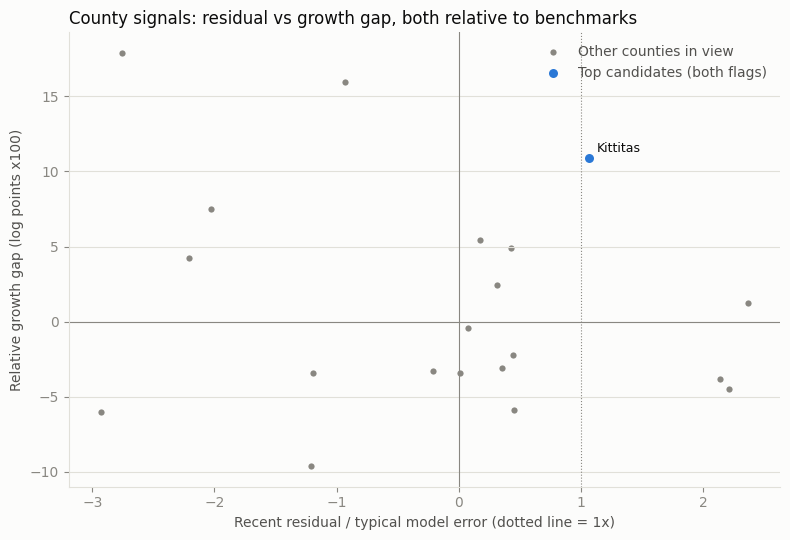

In [11]:
plots.signal_scatter(ranked, config.RESIDUAL_Z_MIN);

### Secondary view: dealer sales

In [12]:
ranked_sales = load_processed("signals_sales")
ranked_sales.loc[ranked_sales["residual_flag"] | ranked_sales["growth_flag"], ["county", "test_years_above", "test_years", "residual_pct", "residual_z", "tire_growth_log", "vehicle_growth_log", "relative_gap_log", "residual_flag", "growth_flag", "top_candidate"]]

,county,test_years_above,test_years,residual_pct,residual_z,tire_growth_log,vehicle_growth_log,relative_gap_log,residual_flag,growth_flag,top_candidate
0,Asotin,4,4,1.214,4.518,0.147,-0.048,0.169,True,True,True
1,Kittitas,4,4,0.497,2.295,0.128,-0.004,0.107,True,True,True
2,Island,2,4,0.080,0.438,0.050,-0.056,0.080,False,True,False
3,Jefferson,4,4,0.673,2.925,0.026,-0.038,0.038,True,False,False
4,Mason,2,4,-0.003,-0.016,0.151,-0.021,0.147,False,True,False
5,Grant,4,4,0.495,2.286,0.085,0.049,0.010,True,False,False
7,Skagit,0,4,-0.115,-0.697,0.143,-0.040,0.157,False,True,False
8,Okanogan,4,4,0.218,1.121,0.009,0.008,-0.025,True,False,False
10,Adams,4,4,1.992,6.232,-0.052,0.058,-0.136,True,False,False
12,Kitsap,0,4,-0.264,-1.744,0.170,-0.032,0.176,False,True,False


### Do candidates change with the dealer measure?

In [13]:
comparison = load_processed("candidates_by_view")
comparison[comparison.filter(like="top_candidate").eq(True).any(axis=1)]

,county,residual_flag_cbp_emp,growth_flag_cbp_emp,top_candidate_cbp_emp,residual_flag_sales,growth_flag_sales,top_candidate_sales
0,Kittitas,True,True,True,True,True,True
20,Asotin,NaN,NaN,NaN,True,True,True


### Plausible explanations other than dealer loss (hypotheses, untested)

Each flagged county could show a high or fast-growing tire-dealer signal for reasons that have nothing to do with dealerships losing tire business. These are **hypotheses** to check, not findings.

| County | Tier | Hypotheses other than dealer loss |
|---|---|---|
| Kittitas | Robust | **One city drives it:** 73% of the growth is Cle Elum, where tire-dealer sales jumped about 40-fold from 2024Q2 with the same number of taxpayers. That points to a new or expanded shop, a business reclassified into 441340, or a change in reporting location. Cle Elum sits at the east foot of Snoqualmie Pass on I-90, so through-traffic (winter tires, chains, roadside replacements) is plausible demand. Central Washington University students' cars may be registered elsewhere. The CBP residual is only 1.06× typical error. |
| Asotin | Watch | **Cross-border market:** 96% of the growth is Clarkston, which forms one metro with Lewiston, Idaho. Clarkston tire shops may serve Idaho residents, while Asotin residents may buy cars from Lewiston dealers. That would make local dealer activity (about $1M a year in disclosed sales, often hidden) understate the market and inflate the residual. Not assessable with CBP data. |


In [14]:
flagged = signals.flagged_counties(comparison, ["cbp_emp", "sales"])
flagged

['Kittitas', 'Asotin']

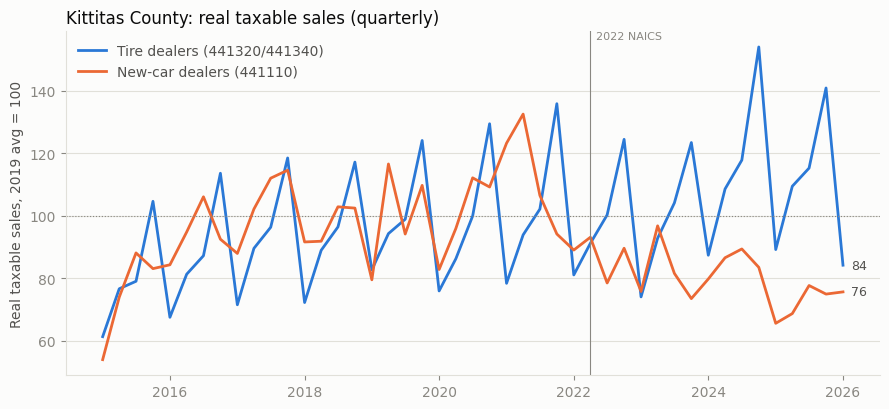

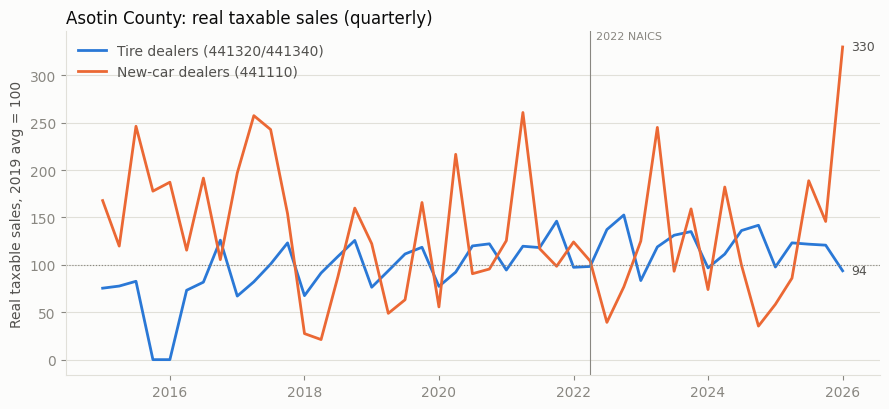

In [15]:
for county in flagged:
    plots.county_index(cq, county)

### Other findings

In the CBP model, dealer employment adds little once vehicles are included: its coefficient is 0.15 (p = 0.30), against 0.65 for vehicles (p < 0.001). In this data, tire-dealer sales track cars on the road more than dealer presence. This is an observation from 20 Washington counties over 2017–2023, not a general conclusion.

In [16]:
load_processed("coefficients_cbp_emp")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.652,0.163,0.000,100,0.955
1,log_dealer,0.148,0.142,0.298,100,0.955


## 7. Caveats

This section lists what limits these results and what each limitation could change. It is the content of `CAVEATS.md`.

In [17]:
Markdown((config.ROOT / "CAVEATS.md").read_text())

# Caveats

The results are **candidate markets, not proof** that dealerships are losing tire business to independent tire shops. Each caveat below says what it could change.

| # | Caveat | What it could change |
|---|---|---|
| 1 | **One state.** Washington only, because it is the state found that publishes six-digit tire-dealer sales by county (see `reports/state_sales_check.md`). | Nothing here transfers to other states without equivalent data. Washington's tax rules (no income tax, destination sourcing) may make its pattern atypical. |
| 2 | **39 counties, fewer modelled.** Ten small counties are excluded for tire-data suppression (`exclusions.csv`), leaving 29. The primary CBP view also drops 9 counties where CBP does not publish new-car dealer employment in every year 2017–2023: Adams, Asotin, Ferry, Island, Jefferson, Klickitat, Mason, San Juan, Stevens. That leaves **20 counties**. | The regression is small-sample (100 county-years in the CBP view). Rankings and flags move when counties are added or dropped. Jefferson, a top candidate under dealer sales, cannot be assessed in the CBP view at all. |
| 3 | **Taxable sales only.** DOR reports sales subject to local retail sales tax. Sales to tax-exempt buyers, resale and out-of-state deliveries are excluded. | Counties where tire dealers sell heavily to exempt buyers (government fleets, farms, resellers) look smaller than they are, which biases their residual down. |
| 4 | **Hidden ("D") cells.** Cells with fewer than 3 taxpayers are suppressed. County totals are sums of *disclosed* cells, so they are lower bounds. Each hidden cell holds 1–2 taxpayers. | Counties with many small towns understate their sales. A change in suppression over time (a town crossing 3 shops) can create artificial growth. Hidden counts per county-quarter are in `county_quarter.csv` (`hidden_cells`, `hidden_share_ub`). |
| 5 | **Dealer tire sales cannot be separated.** New-car dealers (441110) report one taxable-sales total covering vehicles, parts, service and tires. Dealer sales therefore **mostly reflect new-car sales, which fell nationally after 2019** (pandemic and semiconductor-shortage supply limits). Dealer activity (CBP employment primary, dealer sales secondary) is now used **only in the level model**, as a control for local dealer presence. The growth signal compares tire sales with registered vehicles instead. | Dealer activity no longer drives the growth signal. In the level model it is a weak control for dealer presence, not a measure of dealers' tire business. |
| 6 | **Big-box, warehouse-club and online sellers are not captured.** Costco, Walmart and online tire sales are classified outside 441320/441340 (e.g. 455 general merchandise, or remote sellers). | Counties where those channels are strong look under-served by tire shops (negative residual) when demand is being met elsewhere. The analysis cannot see where dealers' tire customers actually go. |
| 7 | **Demand is estimated from registrations.** These are DOL registration *transactions* for Passenger Vehicle + Truck by owner's county and calendar year. Annual renewal makes this approximate the fleet, but multi-transaction vehicles and fleet registrations add noise. DOL monthly data start January 2017, so **modelling runs from 2017, not 2015** (train 2017–2021; test 2022–2025 in the dealer-sales view, 2022–2023 in the CBP view). | Vehicle-mix differences (trucks vs cars, studded-tire use in the east) are not in the model. The training period is two years shorter than specified. |
| 8 | **Residuals have other explanations.** A positive residual can reflect cross-county shopping (a regional hub drawing rural buyers), fleet and commercial buyers, a different vehicle mix, or where a multi-location business reports its sales. | High-residual counties are often regional retail centres. A residual is a reason to look, not evidence of dealer loss. |
| 9 | **Inflation adjustment uses national CPIs.** Tire sales use the BLS CPI-U *Tires* index (`CUUR0000SETC01`). New-car-dealer sales use *New vehicles* (`CUUR0000SETA01`); the brief only named a tire CPI, and deflating car sales by tire prices would distort the growth gap. Both are U.S. city averages; there is no Washington-specific index. **October 2025 is missing** for tires (BLS: lapse in appropriations), so 2025Q4 averages November and December. | Washington price trends may differ from national ones. Levels across counties are unaffected (one deflator per year). The growth gap shifts by the difference between the two CPIs' growth if the other deflator choice is made. |
| 10 | **2022 NAICS switch.** Tire dealers moved from 441320 to 441340 in 2022Q2, and the two codes are combined into one series. The switch is checked in `naics_transition_check.csv`. | If some businesses were reclassified into or out of tire dealers at the switch, the series has a level shift that would show up as growth. |
| 11 | **Evaluation is cross-sectional.** Baseline and model are both calibrated each year to the actual total of the counties in the view, because year effects for unseen test years cannot be estimated. The metrics measure how well each method *allocates* sales across counties, not how well it forecasts the state level. | A model that wins here can still forecast statewide trends badly. The signals do not use statewide forecasts. |
| 12 | **Residual signals are out of sample and scaled by model error.** Residuals come from the model trained on 2017–2021 and predicted on the test years. A county is flagged only if actual sales were above expected in *every* recent test year **and** the mean recent log residual exceeds 1× the model's typical error (the median absolute test log error over all county-years). | The threshold is a convention, not a significance test. The typical error itself is estimated from only 40 (CBP) or 116 (sales) county-years. |
| 13 | **Thurston total gap.** The sum of Thurston's jurisdictions is 0.9% below DOR's own county total for NAICS 441 (2025Q4), unexplained (see `reports/location_codes.md`). | This is negligible for ranking. It suggests some sales may be assigned only at county level. |
| 14 | **CBP view is short and noisy.** CBP is released with a lag: 2023 is the latest year, and the 2024 endpoint returns 404. In the CBP view, the level model's test years are 2022–2023 only, so "all recent years" means 2 years. The growth gap uses registrations and runs 2019→2025 in both views. CBP counts mid-March employment at establishment location and applies noise infusion. In the CBP model, the dealer-employment coefficient is small and not significant (0.15, p = 0.30); vehicles do most of the work. | "Above expected in all recent years" is a weak filter with 2 years. Kittitas's CBP residual is 1.06× typical error, just over the 1× threshold. A re-run with CBP 2024 could move it either way. |
| 15 | **Growth gap vs registered vehicles.** The gap is real tire-dealer log growth minus registered-vehicle log growth, 2019→2025, each net of the trend across the counties in the view. Real tire growth must also be positive. Subtracting the trend shifts every county by the same constant, so the **ranking is identical to the raw gap**; only the zero line moves. The top-quartile cut depends on the view's county set (top 5 of 20 under CBP, top 8 of 29 under dealer sales). | Tire spending per vehicle can rise for reasons other than a shift between sellers: larger or pricier tires, faster EV tire wear, or fleet growth not in Passenger/Truck registrations. Grant drops out under this comparison: its tire growth (+9%) is close to its vehicle growth (+5%). |
| 16 | **Non-dealer explanations in the notebook are hypotheses.** They are plausible alternative explanations, not tested. | Any of them could account for a county's signal without any dealer losing tire business. |
| 17 | **Dealer tire share is not observable.** No public source splits tire sales by seller type within a county. When tire-dealer sales grow faster than vehicles, tire dealers are taking a larger share of local tire spending (or tire spending per vehicle is rising). | The share gain could come from **dealerships, big-box or warehouse clubs, or online sellers**, or from no one, if total tire spending per vehicle grew. The signal cannot say which; it does not show that dealers lost tire business. |
| 18 | **One jurisdiction can drive a county.** `candidate_tiers.csv` reports the share of each county's disclosed tire-sales growth (nominal, 2019→2025) that comes from its single largest jurisdiction. Kittitas: 73% from **Cle Elum**, where tire-dealer sales jumped from about $20k to about $900k a quarter starting 2024Q2, with the same 5–8 taxpayers. Asotin: 96% from **Clarkston**. | The Kittitas signal probably reflects one business opening, expanding, being reclassified into 441340 or changing where it reports sales. Without Cle Elum, Kittitas's tire sales are flat to falling since 2022. Confirming either county starts with identifying that business. |
| 19 | **Results are candidates, not proof.** | Confirming any county needs company data (dealer service and tire revenue, customer addresses) or field checks. |


## 8. With company data

This section describes how the county screen would become a list of specific dealerships. With a company's own data, each dealership's tire and service revenue, which public data cannot separate from car sales, and its customer addresses would replace the county-level proxies used here. Comparing each dealer's tire revenue per vehicle sold or serviced against peers, and against independent tire-dealer sales in its market area, would show which dealerships are under-capturing tire demand and turn the county signals into a ranked, dealer-level target list.
